# IMU Activity Recognition and Fall Detection

> **Who is this for:** learners who finished [01 - Signals, frequency and sensor basics](01_signals_frequency_and_sensor_basics.ipynb) and want to build a real-world style system on motion sensors: the kind of AI inside fitness trackers, smartwatches and fall-alarm pendants for older people.
>
> **What you will learn:**
> - how an **accelerometer** and a **gyroscope** work: axes, gravity, **g** units, orientation and tilt
> - how to build a **synthetic but realistic IMU dataset**: several simulated people doing walk, stairs, sit, stand, lie down, tricky "look-alike" movements, and **falls** (free-fall dip, impact spike, stillness afterwards)
> - **windowing with overlap**, and **features** for motion data
> - three ways to detect falls: a **threshold rule**, **tree models** (random forest, gradient boosting) and a **small neural network** on raw windows
> - honest evaluation with **leave-one-subject-out** cross-validation
> - why **accuracy misleads** when falls are rare, and the metrics that matter: **sensitivity**, **specificity**, **precision**, **false alarms per day**, **precision-recall curves**; plus **class-imbalance** handling
> - **on-device (edge)** limits: latency, battery, model size, **8-bit quantization**, and a cheap-filter-first **cascade**
> - other fall sensors (camera, radar, WiFi, floor vibration), **privacy** trade-offs, and **deployment** concerns (alert escalation, human confirmation, medical-device rules)
>
> **Prerequisites:** [01 - Signals, frequency and sensor basics](01_signals_frequency_and_sensor_basics.ipynb), [your first ML model](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb). Helpful: [time series basics](../04_Forecasting/01_time_series_basics.ipynb).
>
> **Time needed:** about 2-3 hours to read and play (the notebook runs in about 1-2 minutes on a laptop CPU).
>
> **Runs on:** CPU, no API key, no internet. Uses numpy, scipy, scikit-learn and matplotlib. All data is **synthetic**: it imitates the shape of real IMU recordings, but every number in this notebook is illustrative, not a clinical result.

**Why this matters.** Falls are a leading cause of injury for older adults, and lying on the floor for a long time after a fall makes the outcome much worse (see the WHO falls fact sheet in Further reading). A device that **reliably calls for help** and **does not cry wolf** is a genuinely useful AI product. Getting both at once is the hard part, and it is what this notebook is about.

## 0. Setup

In [1]:
import time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_curve,
                             average_precision_score, f1_score)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # keep the output readable

SEED = 7
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (9, 3); plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=3, suppress=True)
FS = 50                       # sampling rate: 50 samples per second (common for wearables)
print("ready")

ready


## 1. Accelerometer and gyroscope basics

An **IMU (inertial measurement unit)** is a small chip that usually holds:

| Sensor | Measures | Unit | Analogy |
|---|---|---|---|
| **Accelerometer** | acceleration along 3 axes (x, y, z), *including gravity* | **g** (1 g ≈ 9.81 m/s²) or m/s² | a ball on springs inside a box: when the box speeds up, the ball presses on one side |
| **Gyroscope** | rotation speed around 3 axes | degrees per second (deg/s, "dps") or rad/s | a spinning top that resists turning |
| **Magnetometer** (optional, makes a 9-axis IMU) | Earth's magnetic field | microtesla (µT) | a compass |

**Axes.** The sensor has its own x, y and z directions printed on the chip. In this notebook the device is clipped to the **waist**: when the person stands, **x points forward**, **y points left** and **z points up**.

**Gravity is always there.** An accelerometer lying still on a table does not read 0. It reads **+1 g on the axis that points up**, because the table pushes it up against gravity. This has two big consequences:
- From the gravity direction we get **orientation (tilt)**: standing gives about (0, 0, 1) g; lying on the back gives about (1, 0, 0) g.
- In **free fall** the device and the springs fall together, so the reading drops towards **0 g**. That dip is the first sign of a fall.

**Simple analogy.** You in a lift: when it starts going down fast, you feel lighter (the reading drops). When it stops suddenly, you feel heavier (a spike). A fall is an extreme version: a big "lighter" moment, then a very hard stop on the floor.

**Tilt from gravity.** The angle between the measured gravity direction and "straight up" (z) is

`tilt = arccos(a_z / |a|)`

where `|a| = sqrt(a_x² + a_y² + a_z²)` is the **magnitude** (total size) of the acceleration vector. The magnitude does not depend on how the device is rotated, which makes it a very robust feature.

In [2]:
def tilt_deg(acc):
    """Angle (degrees) between the measured acceleration and the device's z axis."""
    acc = np.atleast_2d(acc)
    return np.degrees(np.arccos(np.clip(acc[:, 2] / np.linalg.norm(acc, axis=1), -1, 1)))

for name, a in {"standing": [0, 0, 1], "sitting, leaning back 25 deg": [-0.42, 0, 0.91],
                "lying on back": [1, 0, 0], "lying on left side": [0, 1, 0]}.items():
    print(f"{name:<30} acc = {a} g  ->  tilt = {tilt_deg(np.array(a, float))[0]:5.1f} deg")

standing                       acc = [0, 0, 1] g  ->  tilt =   0.0 deg
sitting, leaning back 25 deg   acc = [-0.42, 0, 0.91] g  ->  tilt =  24.8 deg
lying on back                  acc = [1, 0, 0] g  ->  tilt =  90.0 deg
lying on left side             acc = [0, 1, 0] g  ->  tilt =  90.0 deg


## 2. A synthetic but realistic IMU data generator

Real fall data is rare and hard to collect: you cannot ask older people to fall. Public datasets mostly contain **young volunteers falling onto mattresses** (see SisFall and others in Further reading). Here we write a **generator** that copies the typical shapes reported in the literature:

| Activity | What the waist IMU shows (simplified) |
|---|---|
| stand | gravity on z, tiny body sway |
| sit | gravity tilted (person leans back), very little motion |
| lie | gravity on x or y (on the back, front or side), almost no motion |
| walk | periodic bounce at the **step frequency** (about 1.6-2.1 steps per second), sway at half that rate |
| stairs | slower, bigger, slightly tilted bounce (easy to confuse with walking) |
| **fall** | (1) **free-fall dip**: magnitude drops below 1 g for 0.3-0.6 s while the body rotates fast; (2) **impact spike**: a short peak of about 2-6 g; (3) **stillness** lying on the floor, often in an unusual orientation |

To make the problem honest, we also add **look-alikes** (ADLs that resemble falls; **ADL = activity of daily living**):
- **plopping into a chair** (small dip + impact, but ends sitting),
- **lying down quickly on a bed** (rotation + soft impact, ends lying),
- **jumping** (a real free-fall phase + a hard landing, but ends standing).

And some falls are **hard**: a soft fall onto a sofa-height surface, or a fall that ends **sitting** against a wall.

Each simulated **subject** (person) has their own step rate, walking strength, device mounting angle, sensor bias and noise level. This is what makes "new person" evaluation hard, just like in real life.

In [3]:
UP = np.array([0.0, 0.0, 1.0])
_sway_sos = signal.butter(2, 0.6, fs=FS, output="sos")           # slow body sway (below 0.6 Hz)

def sway(n, scale):
    """Slow random wobble (n samples x 3 axes) with a given standard deviation."""
    w = signal.sosfilt(_sway_sos, rng.normal(size=(n, 3)), axis=0)
    return w / (w.std() + 1e-9) * scale

def sit_vec(subj):   # leaning back: gravity moves from z towards -x
    p = np.radians(subj["sit_lean"]); return np.array([-np.sin(p), 0, np.cos(p)])

def lie_vec():       # back, front, left side, right side
    return [np.array([1.0, 0, 0]), np.array([-1.0, 0, 0]), np.array([0, 1.0, 0]), np.array([0, -1.0, 0])][rng.integers(4)]

def static(g, seconds, motion=0.01, rot=1.0):
    """Holding a posture: gravity vector g plus a small sway."""
    n = int(seconds * FS)
    return np.tile(g, (n, 1)) + sway(n, motion), sway(n, rot)

def walking(seconds, subj, stairs=False):
    n = int(seconds * FS); t = np.arange(n) / FS
    f = subj["step_f"] * (0.8 if stairs else 1.0) * rng.uniform(0.95, 1.05)
    A = subj["walk_amp"] * (1.35 if stairs else 1.0) * rng.uniform(0.9, 1.1)
    lean = np.radians(rng.uniform(5, 15) if stairs else rng.uniform(0, 4))  # stairs: lean forward
    g = np.array([np.sin(lean), 0, np.cos(lean)])
    ph = rng.uniform(0, 2 * np.pi)
    acc = np.column_stack([0.6 * A * np.sin(2 * np.pi * f * t + ph + 1.2),          # forward
                           0.4 * A * np.sin(np.pi * f * t + ph),                    # side-to-side
                           A * np.sin(2 * np.pi * f * t + ph)
                           + 0.35 * A * np.sin(4 * np.pi * f * t + 2 * ph)])        # up-down bounce
    if stairs:   # each step up has an extra push
        acc[:, 2] += 0.25 * A * np.sin(np.pi * f * t + ph) ** 2
    k = 1.3 if stairs else 1.0
    gyro = np.column_stack([15 * k * np.sin(np.pi * f * t + ph), 10 * k * np.sin(2 * np.pi * f * t + ph + 0.5),
                            20 * k * np.sin(np.pi * f * t + ph + 1)])
    return g + acc + sway(n, 0.03), gyro + sway(n, 3)

def transition(g0, g1, seconds, dip=None, impact=None, push=None):
    """Move from posture g0 to g1. Optional free-fall dip, impact spike at the end, push-off at the start."""
    n = max(int(seconds * FS), 4)
    s = np.linspace(0, 1, n); s = s * s * (3 - 2 * s)                     # smooth 0 -> 1
    g = (1 - s)[:, None] * g0 + s[:, None] * g1
    g /= np.linalg.norm(g, axis=1, keepdims=True)
    gyro = np.degrees(np.cross(g, np.gradient(g, axis=0) * FS))            # rotation speed from the tilt change
    scale = np.ones(n)
    if dip is not None:                                                    # gravity reading drops (free fall)
        depth, frac = dip                                                  # how deep, which fraction of the move
        mid = int(n * (1 - frac / 2)) - 3
        width = max(int(n * frac / 2), 2)
        scale -= (1 - depth) * np.exp(-0.5 * ((np.arange(n) - mid) / (width / 1.5)) ** 4)
    acc = g * scale[:, None]
    if push is not None:                                                   # push-off before a jump
        acc[: n // 4] += np.outer(np.hanning(n // 4), g0) * (push - 1)
    if impact is not None:                                                 # short spike as the body hits something
        k = np.arange(n); width = rng.uniform(1.0, 2.0)                    # in samples (20-40 ms)
        pulse = np.exp(-0.5 * ((k - (n - 3)) / width) ** 2)
        direction = g1 + rng.normal(0, 0.3, 3); direction /= np.linalg.norm(direction)
        acc += np.outer(pulse, direction) * (impact - 1)
    return acc + sway(n, 0.02), gyro + sway(n, 4)

Now the building blocks are combined into a ~15 minute "day" for each subject. A **script** is a short sequence like "walk, then stand" or "walk, fall, lie still, get up". Every script starts and ends standing, so they can be chained in any order. We record, for each sample, the activity label and, for falls, the exact sample of the **impact**.

In [4]:
ACTS = ["stand", "sit", "lie", "walk", "stairs"]          # the 5 "pure" activities
LABEL = {a: i for i, a in enumerate(ACTS)}; LABEL["transition"] = 5; LABEL["fall"] = 6

def make_subject():
    return {"step_f": rng.uniform(1.6, 2.1), "walk_amp": rng.uniform(0.15, 0.35),
            "sit_lean": rng.uniform(12, 35), "tilt": rng.normal(0, 8, 3),           # mounting angle (deg)
            "acc_bias": rng.normal(0, 0.03, 3), "gyro_bias": rng.normal(0, 1.5, 3),
            "acc_noise": rng.uniform(0.01, 0.03), "gyro_noise": rng.uniform(1.0, 3.0)}

def rotation(deg_xyz):
    ax, ay, az = np.radians(deg_xyz)
    Rx = np.array([[1, 0, 0], [0, np.cos(ax), -np.sin(ax)], [0, np.sin(ax), np.cos(ax)]])
    Ry = np.array([[np.cos(ay), 0, np.sin(ay)], [0, 1, 0], [-np.sin(ay), 0, np.cos(ay)]])
    Rz = np.array([[np.cos(az), -np.sin(az), 0], [np.sin(az), np.cos(az), 0], [0, 0, 1]])
    return Rz @ Ry @ Rx

def script(kind, subj):
    """Return a list of (acc, gyro, label name) pieces for one short scenario."""
    U = lambda a, b: rng.uniform(a, b)
    if kind == "walk":
        return [(*walking(U(20, 60), subj), "walk"), (*static(UP, U(5, 20)), "stand")]
    if kind == "stairs":
        return [(*walking(U(8, 20), subj), "walk"), (*walking(U(15, 40), subj, stairs=True), "stairs"),
                (*walking(U(5, 15), subj), "walk"), (*static(UP, U(3, 8)), "stand")]
    if kind == "sit":
        g = sit_vec(subj)
        fast = rng.random() < 0.35                            # "plop" into the chair: look-alike
        down = transition(UP, g, U(0.6, 1.0), dip=(U(0.55, 0.8), 0.4), impact=U(1.6, 2.8)) if fast \
            else transition(UP, g, U(1.2, 2.0), impact=U(1.05, 1.3))
        return [(*down, "transition"), (*static(g, U(20, 90), 0.008), "sit"),
                (*transition(g, UP, U(1.0, 2.0)), "transition"), (*static(UP, U(5, 15)), "stand")]
    if kind == "lie":
        g = lie_vec(); fast = rng.random() < 0.4               # flop onto the bed quickly: look-alike
        down = transition(UP, g, U(0.8, 1.3), dip=(U(0.45, 0.75), 0.5), impact=U(1.5, 2.4)) if fast \
            else transition(UP, g, U(2.0, 3.5), impact=U(1.05, 1.3))
        return [(*down, "transition"), (*static(g, U(20, 60), 0.006), "lie"),
                (*transition(g, UP, U(2.0, 4.0)), "transition"), (*static(UP, U(5, 15)), "stand")]
    if kind == "jump":                                         # real free fall + hard landing, ends standing
        pieces = []
        for _ in range(rng.integers(1, 4)):
            pieces += [(*transition(UP, UP, U(0.5, 0.7), dip=(U(0.05, 0.25), 0.5), impact=U(2.2, 4.5),
                                    push=U(1.4, 2.0)), "transition"), (*static(UP, U(2, 5), 0.02), "stand")]
        return pieces
    if kind == "fall":
        start = walking(U(4, 12), subj) if rng.random() < 0.6 else static(UP, U(4, 10))
        soft = rng.random() < 0.2                              # soft or partial falls are the hardest
        end = sit_vec(subj) if rng.random() < 0.15 else lie_vec()   # some falls end sitting against a wall
        fall = transition(UP, end, U(0.6, 1.0), dip=(U(0.35, 0.65) if soft else U(0.05, 0.45), 0.6),
                          impact=U(1.6, 2.4) if soft else U(2.4, 6.0))
        still = static(end, U(3, 15), 0.004 if rng.random() < 0.7 else 0.03)   # sometimes moving a bit
        return [(*start, "walk" if start[0].std() > 0.05 else "stand"), (*fall, "fall"), (*still, "transition"),
                (*transition(end, UP, U(2.5, 5.0)), "transition"), (*static(UP, U(5, 10)), "stand")]

def record_day(subj, minutes=20, n_falls=6):
    kinds = ["walk", "stairs", "sit", "lie", "jump", "walk", "sit"]
    plan, total = [], 0
    while total < minutes * 60:                                # random daily routine
        k = kinds[rng.integers(len(kinds))]; plan.append(k); total += 45
    for _ in range(n_falls):
        plan.insert(rng.integers(len(plan)), "fall")
    acc, gyro, lab, impacts = [], [], [], []
    n = 0
    for k in plan:
        for a, g, name in script(k, subj):
            acc.append(a); gyro.append(g); lab.append(np.full(len(a), LABEL[name]))
            if name == "fall":
                impacts.append(n + len(a) - 3)                 # sample index of the impact peak
            n += len(a)
    acc, gyro, lab = np.vstack(acc), np.vstack(gyro), np.concatenate(lab)
    R = rotation(subj["tilt"])                                 # how this person wears the device
    acc = acc @ R.T + subj["acc_bias"] + rng.normal(0, subj["acc_noise"], acc.shape)
    gyro = gyro @ R.T + subj["gyro_bias"] + rng.normal(0, subj["gyro_noise"], gyro.shape)
    return acc, gyro, lab, np.array(impacts)

N_SUBJECTS = 10
subjects = [make_subject() for _ in range(N_SUBJECTS)]
days = [record_day(s, minutes=15, n_falls=int(rng.integers(4, 8))) for s in subjects]
hours = sum(len(d[0]) for d in days) / FS / 3600
print(f"{N_SUBJECTS} subjects, {hours:.2f} hours of data, {sum(len(d[3]) for d in days)} falls in total")

10 subjects, 3.42 hours of data, 58 falls in total


Let us look at one fall and one jump next to each other. They share a free-fall dip and an impact spike. The big difference is what happens **after** the impact: lying still in a new orientation vs standing up straight.

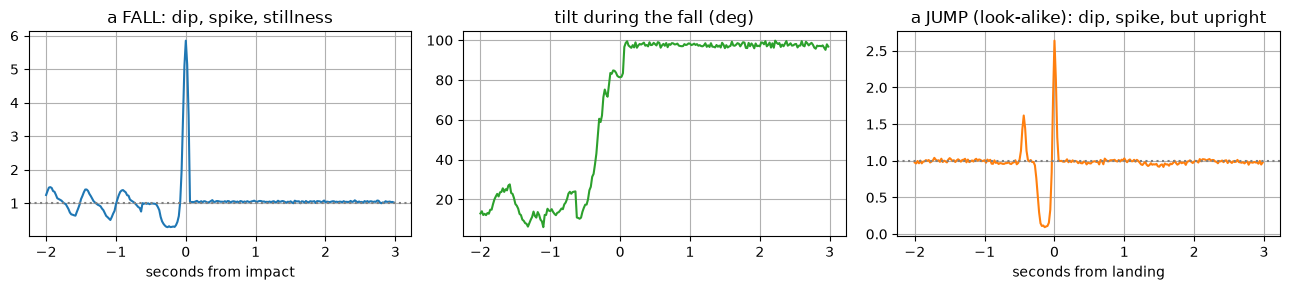

In [5]:
acc, gyro, lab, imp = days[0]
amag = np.linalg.norm(acc, axis=1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
i = imp[(imp > 2 * FS) & (imp < len(acc) - 3 * FS)][0]; seg = slice(i - 2 * FS, i + 3 * FS); tt = (np.arange(seg.stop - seg.start) - 2 * FS) / FS
axes[0].plot(tt, amag[seg], label="|acc| (g)"); axes[0].axhline(1, color="gray", ls=":")
axes[0].set_title("a FALL: dip, spike, stillness"); axes[0].set_xlabel("seconds from impact")
axes[1].plot(tt, tilt_deg(acc[seg]), color="C2"); axes[1].set_title("tilt during the fall (deg)")
# find a jump landing: a big spike that is not a fall, and the person is upright 1 s later
for acc_j, _, lab_j, _ in days:
    am_j = np.linalg.norm(acc_j, axis=1)
    cand = [s for s in np.where((am_j > 2.2) & (lab_j == LABEL["transition"]))[0]
            if 2 * FS < s < len(am_j) - 3 * FS and tilt_deg(acc_j[s + FS])[0] < 30]
    if cand:
        break
j = cand[0]; seg2 = slice(j - 2 * FS, j + 3 * FS)
axes[2].plot(tt, am_j[seg2], color="C1"); axes[2].axhline(1, color="gray", ls=":")
axes[2].set_title("a JUMP (look-alike): dip, spike, but upright"); axes[2].set_xlabel("seconds from landing")
plt.tight_layout(); plt.show()

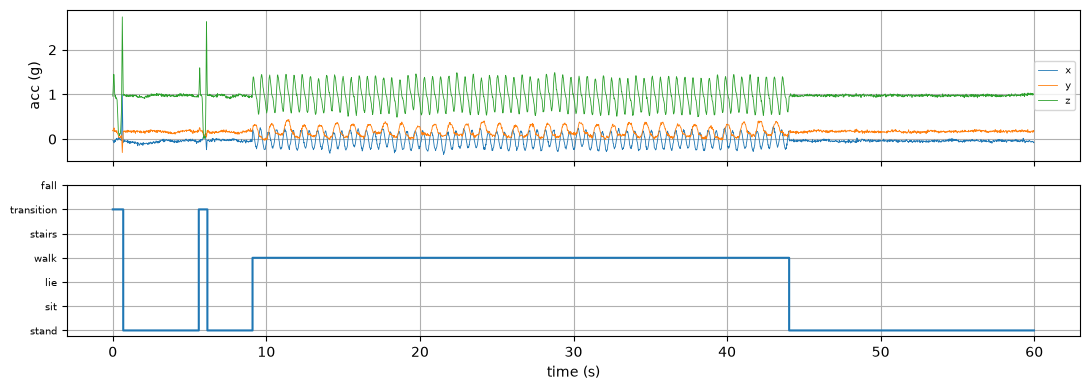

In [6]:
# A minute of normal life for one subject: walking, standing, sitting...
seg = slice(0, 60 * FS)
fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
axes[0].plot(np.arange(60 * FS) / FS, acc[seg], lw=0.6); axes[0].legend(["x", "y", "z"], fontsize=7, loc="right")
axes[0].set_ylabel("acc (g)")
axes[1].plot(np.arange(60 * FS) / FS, lab[seg], drawstyle="steps-post")
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(ACTS + ["transition", "fall"], fontsize=7)
axes[1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

## 3. Windowing with overlap

**What it is.** A model cannot look at a 20-minute stream at once. We cut it into short **windows** and make one prediction per window. Common choice for activity recognition: **2.56 s windows (128 samples at 50 Hz) with 50% overlap**, used for example in the well-known UCI HAR dataset.

**Simple analogy.** Reading a long receipt through a small magnifying glass that you slide half its width each time, so nothing falls between two looks.

**How it works.**

```
stream:   |----------------------------------------------------------->
window 1: [=======]
window 2:     [=======]          step = half a window (50% overlap)
window 3:         [=======]
```

- **Longer windows**: more context and better frequency resolution (notebook 01), but slower to react and more likely to mix two activities.
- **Overlap**: more training examples and fewer events cut in half, at the cost of more computation.

**Labels.** For activity recognition we keep only "pure" windows (at least 90% one activity). For fall detection a window is **positive** if it contains a fall's impact sample, so each fall appears in about two windows.

In [7]:
WIN, STEP = 128, 64                       # 2.56 s windows, 50% overlap

def make_windows(days):
    A, G, act, is_fall, fall_id, subj, start = [], [], [], [], [], [], []
    fid = 0
    for s, (acc, gyro, lab, imp) in enumerate(days):
        for st in range(0, len(acc) - WIN + 1, STEP):
            A.append(acc[st:st + WIN]); G.append(gyro[st:st + WIN])
            counts = np.bincount(lab[st:st + WIN], minlength=7)
            act.append(counts.argmax() if counts.max() >= 0.9 * WIN and counts.argmax() < 5 else -1)
            inside = np.where((imp >= st) & (imp < st + WIN))[0]
            is_fall.append(len(inside) > 0); fall_id.append(fid + inside[0] if len(inside) else -1)
            subj.append(s); start.append(st)
        fid += len(imp)
    return (np.array(A), np.array(G), np.array(act), np.array(is_fall), np.array(fall_id),
            np.array(subj), np.array(start))

A, Gy, act, is_fall, fall_id, subj_w, start_w = make_windows(days)
print("windows:", A.shape, "(windows, samples, axes)")
print(f"pure activity windows: {(act >= 0).sum()}, fall windows: {is_fall.sum()} "
      f"({100 * is_fall.mean():.1f}% of all windows)")

windows: (9603, 128, 3) (windows, samples, axes)
pure activity windows: 7778, fall windows: 116 (1.2% of all windows)


## 4. Features for motion data

We turn each window into about 30 numbers (see notebook 01, section 14, for the general idea). For fall detection, the most physical features are:
- **min and max of |acc|** (the dip and the spike) and the **time between them**,
- the **largest jerk** (jerk = how fast acceleration changes; impacts have a huge jerk),
- **gyroscope magnitude** (how fast the body rotated),
- **tilt at the end** of the window and **tilt change** from start to end (posture after the event),
- **stillness after the peak** (low variance = lying motionless).

In [8]:
def window_features(acc, gyro):
    am = np.linalg.norm(acc, axis=1); gm = np.linalg.norm(gyro, axis=1)
    i_max, i_min = am.argmax(), am.argmin()
    first, last = acc[:25].mean(0), acc[-25:].mean(0)
    cosang = first @ last / (np.linalg.norm(first) * np.linalg.norm(last))
    after = am[i_max + 10:] if i_max + 10 < len(am) - 5 else am[-5:]
    spec = np.abs(np.fft.rfft((am - am.mean()) * np.hanning(len(am))))
    f = np.fft.rfftfreq(len(am), 1 / FS)
    feats = [am.mean(), am.std(), am.min(), am.max(), am.max() - am.min(),
             (i_max - i_min) / FS, stats.kurtosis(am), np.abs(np.diff(am)).max() * FS,
             gm.mean(), gm.std(), gm.max(),
             *acc.mean(0), *acc.std(0), *gyro.std(0),
             tilt_deg(last)[0], np.degrees(np.arccos(np.clip(cosang, -1, 1))),
             after.std(), f[spec.argmax()], spec[(f > 0.5) & (f < 3)].sum() / (spec.sum() + 1e-9)]
    return feats

FEATURE_NAMES = ["am_mean", "am_std", "am_min", "am_max", "am_range", "t_min_to_max", "am_kurt", "max_jerk",
                 "gm_mean", "gm_std", "gm_max", "ax_mean", "ay_mean", "az_mean", "ax_std", "ay_std", "az_std",
                 "gx_std", "gy_std", "gz_std", "tilt_end", "tilt_change", "still_after_peak", "dom_freq",
                 "walk_band_ratio"]
X = np.array([window_features(a, g) for a, g in zip(A, Gy)])
print("feature table:", X.shape)

feature table: (9603, 25)


## 5. Part A: activity recognition, and why you must split by person

First the classic **HAR (human activity recognition)** task: which of the 5 activities is this window? We compare two ways to test the same random forest:
- **random 5-fold split**: windows of the *same person* end up in both training and test sets,
- **leave-one-subject-out (LOSO)**: train on 9 people, test on the 10th, repeat for each person. This answers the real question: *"will it work for a new customer?"*

random-split accuracy : 0.983   (looks great, but is optimistic)
LOSO accuracy         : 0.924   (honest: new person)
LOSO accuracy per subject: [1.   0.83 0.99 1.   0.98 0.89 0.62 0.99 0.98 0.98]


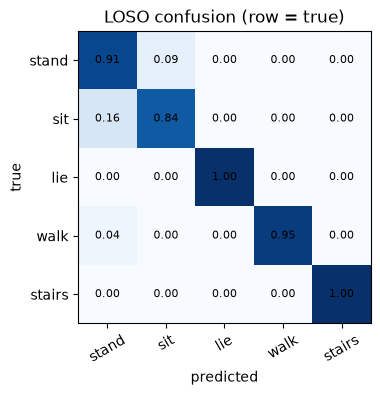

In [9]:
m = act >= 0
Xa, ya, ga = X[m], act[m], subj_w[m]
rf = RandomForestClassifier(n_estimators=40, random_state=SEED, n_jobs=-1)

pred_random = cross_val_predict(rf, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
pred_loso = cross_val_predict(rf, Xa, ya, groups=ga, cv=LeaveOneGroupOut())
print(f"random-split accuracy : {accuracy_score(ya, pred_random):.3f}   (looks great, but is optimistic)")
print(f"LOSO accuracy         : {accuracy_score(ya, pred_loso):.3f}   (honest: new person)")
per_subject = [accuracy_score(ya[ga == s], pred_loso[ga == s]) for s in range(N_SUBJECTS)]
print("LOSO accuracy per subject:", np.round(per_subject, 2))

cm = confusion_matrix(ya, pred_loso, normalize="true")
plt.figure(figsize=(4.5, 3.8)); plt.imshow(cm, cmap="Blues", vmin=0, vmax=1); plt.grid(False)
plt.xticks(range(5), ACTS, rotation=30); plt.yticks(range(5), ACTS)
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("LOSO confusion (row = true)"); plt.show()

**What just happened?** The random split usually scores higher than LOSO, because the model partly learns *each person's* style and mounting angle and then "recognizes" the same person in the test set. Real users are new people, so **always report subject-wise (LOSO or GroupKFold) results**. Typical confusions are realistic too: **walk vs stairs** (similar rhythm) and **sit vs stand** (a waist sensor only sees a small tilt difference). Look at the per-subject numbers too: some people are much harder than others (an unusual mounting angle or walking style), and an average can hide a group of users for whom the product simply does not work. Real products often add a barometer (stairs change air pressure) or a thigh-worn sensor for these.

## 6. Part B: fall detection, why accuracy misleads

Now the binary task: **fall vs not fall**. Look at the class balance first.

In [10]:
yf, gf = is_fall.astype(int), subj_w
print(f"fall windows: {yf.sum()} of {len(yf)} ({100 * yf.mean():.2f}%)")
always_no = np.zeros_like(yf)
print(f"a 'model' that ALWAYS says 'no fall' has accuracy {accuracy_score(yf, always_no):.3f}"
      f" and catches {always_no[yf == 1].sum()} of {yf.sum()} falls")

fall windows: 116 of 9603 (1.21%)
a 'model' that ALWAYS says 'no fall' has accuracy 0.988 and catches 0 of 116 falls


A useless model gets about 99% **accuracy**. In real life falls are even rarer (a person might fall a few times per year, while a device produces tens of thousands of windows per day), so accuracy is meaningless here. We need metrics that look at the two kinds of mistakes separately:

| Metric | Question it answers | Formula |
|---|---|---|
| **Sensitivity** (recall, true positive rate) | Of all real falls, how many did we catch? | TP / (TP + FN) |
| **Specificity** (true negative rate) | Of all normal windows, how many did we correctly leave alone? | TN / (TN + FP) |
| **Precision** (positive predictive value) | When the alarm rings, how often is it a real fall? | TP / (TP + FP) |
| **False alarms per day** | How annoying is the device in daily life? | false alarm events / days of use |
| **Average precision (area under the PR curve)** | One number for the whole precision-recall trade-off | `average_precision_score` |

**TP** = true positive (fall, alarm), **FN** = false negative (missed fall), **FP** = false positive (false alarm), **TN** = true negative.

**Why false alarms per day?** Even 99.9% specificity with one window every 1.28 s gives about 67 false alarms per day (86,400 / 1.28 ≈ 67,500 windows; 0.1% of that ≈ 67). Users switch off or stop wearing a device that cries wolf, and then it catches no falls at all. So both numbers matter: **catch nearly every fall** *and* **keep false alarms to a handful per week or less**.

We will judge every detector with the same **event-level** function: a fall counts as detected if any window containing its impact rings; neighbouring alarm windows are merged into one alarm event.

In [11]:
def evaluate(pred, name="", verbose=True):
    pred = np.asarray(pred).astype(bool)
    tp = (pred & (yf == 1)).sum(); fp = (pred & (yf == 0)).sum()
    fn = (~pred & (yf == 1)).sum(); tn = (~pred & (yf == 0)).sum()
    caught = len(np.unique(fall_id[pred & (fall_id >= 0)])); n_falls = fall_id.max() + 1
    # merge consecutive alarm windows (same subject) into events; count events with no real fall
    false_events = 0
    for s in range(N_SUBJECTS):
        p = pred[subj_w == s]; f = yf[subj_w == s]
        runs = np.split(np.arange(len(p)), np.where(np.diff(p.astype(int)) != 0)[0] + 1)
        false_events += sum(1 for r in runs if p[r[0]] and f[r].sum() == 0)
    res = {"sensitivity(win)": tp / (tp + fn), "specificity(win)": tn / (tn + fp),
           "precision(win)": tp / max(tp + fp, 1), "falls caught": f"{caught}/{n_falls}",
           "false alarms/hour": false_events / hours, "false alarms/day*": false_events / hours * 24}
    if verbose:
        print(f"{name:<34} sens={res['sensitivity(win)']:.2f} spec={res['specificity(win)']:.4f} "
              f"prec={res['precision(win)']:.2f} caught={res['falls caught']:>5} "
              f"FA/day*={res['false alarms/day*']:6.1f}")
    return res

\* **False alarms per day** here = false alarm events per hour of our recordings x 24. Our synthetic "day" is packed with jumps, chair plops and bed flops every few minutes, far more than real life, so this number is **pessimistic and illustrative**. In a real study you would measure it on long, real-life recordings (days or weeks per person).

## 7. Detector 1: a threshold rule (the classic baseline)

Many early commercial and academic fall detectors used simple rules on |acc|, because they are cheap, explainable and need no training data:

```mermaid
flowchart LR
    A[acc magnitude drops below<br/>free-fall threshold] --> B{impact above<br/>impact threshold<br/>within 1 s?}
    B -- no --> N[no alarm]
    B -- yes --> C{optional: lying or tilted<br/>and still afterwards?}
    C -- no --> N
    C -- yes --> Y[ALARM]
```

In [12]:
def threshold_detector(A, ff_th=0.6, impact_th=2.5, posture_check=False):
    out = []
    for acc in A:
        am = np.linalg.norm(acc, axis=1)
        alarm = False
        for i in np.where(am < ff_th)[0]:                     # each free-fall sample...
            j = i + np.argmax(am[i:i + FS])                    # ...the biggest peak in the next 1 s
            if am[j] > impact_th:
                alarm = True
                if posture_check:                              # tilted and fairly still 0.6-1.2 s after impact?
                    post = acc[j + 30:j + 60]
                    alarm = len(post) >= 20 and tilt_deg(post.mean(0))[0] > 40 and \
                        np.linalg.norm(post, axis=1).std() < 0.1
                break
        out.append(alarm)
    return np.array(out)

for kw in [dict(), dict(posture_check=True), dict(ff_th=0.75, impact_th=1.8, posture_check=True)]:
    evaluate(threshold_detector(A, **kw), f"threshold {kw}")

threshold {}                       sens=0.71 spec=0.9916 prec=0.51 caught=43/58 FA/day*= 273.7
threshold {'posture_check': True}  sens=0.31 spec=1.0000 prec=1.00 caught=32/58 FA/day*=   0.0


threshold {'ff_th': 0.75, 'impact_th': 1.8, 'posture_check': True} sens=0.40 spec=0.9987 prec=0.79 caught=40/58 FA/day*=  77.2


**What just happened?** The plain rule (free fall + impact) fires on **jumps** and quick **bed flops**, so it raises many false alarms, and it misses **soft falls** whose dip or spike is too weak. Adding the **posture check** removes most look-alikes that end standing, but also misses falls where the posture check comes too late in the window or the person ends up sitting. Loosening thresholds catches more falls but brings false alarms back. **Every threshold rule is a trade-off you set by hand.** ML lets the data set that trade-off, using many features together.

## 8. Detector 2: tree models with leave-one-subject-out

**Random forest**: many decision trees, each trained on a random sample of the data, voting together. **Gradient boosting**: trees added one after another, each fixing the mistakes of the previous ones (`HistGradientBoostingClassifier` is scikit-learn's fast version). Both work very well on feature tables of this size.

**Class imbalance.** With 1% positives, a model can get a low loss by mostly ignoring falls. Common fixes:
- **class weights** (`class_weight="balanced"`): mistakes on the rare class cost more,
- **resampling**: repeat (oversample) falls or drop some normal windows,
- **threshold moving**: keep the model, but ring the alarm at a probability below 0.5,
- **better data**: collect more falls and more hard look-alikes (often the most effective fix).

We get honest out-of-fold probabilities with LOSO: each person's windows are scored by a model that never saw that person.

In [13]:
logo = LeaveOneGroupOut()
t0 = time.time()
proba = {}
proba["random forest"] = cross_val_predict(
    RandomForestClassifier(n_estimators=40, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    X, yf, groups=gf, cv=logo, method="predict_proba")[:, 1]
proba["random forest, balanced"] = cross_val_predict(
    RandomForestClassifier(n_estimators=40, min_samples_leaf=2, class_weight="balanced_subsample",
                           random_state=SEED, n_jobs=-1),
    X, yf, groups=gf, cv=logo, method="predict_proba")[:, 1]
proba["gradient boosting, balanced"] = cross_val_predict(
    HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, class_weight="balanced", random_state=SEED),
    X, yf, groups=gf, cv=logo, method="predict_proba")[:, 1]
print(f"(LOSO training took {time.time() - t0:.1f} s)")
for name, p in proba.items():
    evaluate(p >= 0.5, f"{name} @0.5")

(LOSO training took 30.7 s)
random forest @0.5                 sens=0.84 spec=0.9993 prec=0.93 caught=52/58 FA/day*=  21.1
random forest, balanced @0.5       sens=0.84 spec=0.9992 prec=0.92 caught=52/58 FA/day*=  28.1
gradient boosting, balanced @0.5   sens=0.88 spec=0.9987 prec=0.89 caught=54/58 FA/day*=  49.1


**What just happened?** All tree models catch far more falls than the threshold rules, with far fewer false alarms than the plain rule. Class weights change only a little at the default 0.5 threshold here; the bigger lever is **where you put the threshold** (section 10). The false-alarm numbers are still far too high for a real product, which is why real systems add a confirmation step (section 13), more training data with hard negatives, and often a second sensor.

## 9. Detector 3: a small neural network on raw windows

Instead of hand-made features, we can feed the **raw** signal to a neural network and let it learn its own features. Here we use scikit-learn's `MLPClassifier` (a **multi-layer perceptron**: layers of weighted sums followed by a simple non-linearity) on each window: 6 channels (3 accelerometer + 3 gyroscope axes) averaged in pairs to 25 Hz (64 x 6 = 384 inputs), plus the |acc| peak of each pair (64 more inputs, 448 in total) so short spikes are not averaged away.

In practice people often use small **1-D CNNs** (convolutional networks that slide filters along time) or **LSTMs/GRUs** (recurrent networks) in PyTorch or TensorFlow for this; the idea is the same. See [deep learning](../05_Deep_Learning/) for those tools.

`MLPClassifier` has no class weights, so we handle imbalance by **oversampling** falls in each training fold. To keep the run time short we use 5 subject-wise folds (`GroupKFold`: 2 people held out each time) instead of 10.

In [14]:
def raw_inputs(A, Gy):
    am = np.linalg.norm(A, axis=2)
    pairs = lambda z: z.reshape(z.shape[0], WIN // 2, 2, -1)
    acc25 = pairs(A).mean(2); gyr25 = pairs(Gy).mean(2) / 100       # gyro scaled to a similar range as acc
    peak25 = am.reshape(len(am), WIN // 2, 2).max(2)
    return np.concatenate([acc25.reshape(len(A), -1), gyr25.reshape(len(A), -1), peak25], axis=1)

R = raw_inputs(A, Gy)
print("raw input table:", R.shape, "= 64 x 3 acc + 64 x 3 gyro + 64 peaks")

def mlp_subjectwise(R, y, groups, oversample=10):
    p = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(R, y, groups):
        idx = np.concatenate([tr] + [tr[y[tr] == 1]] * (oversample - 1))   # repeat the falls
        net = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-3, batch_size=256,
                                                            max_iter=25, random_state=SEED))
        net.fit(R[idx], y[idx]); p[te] = net.predict_proba(R[te])[:, 1]
    return p

t0 = time.time()
proba["small MLP on raw windows"] = mlp_subjectwise(R, yf, gf)
print(f"(subject-wise training took {time.time() - t0:.1f} s)")
evaluate(proba["small MLP on raw windows"] >= 0.5, "small MLP on raw @0.5");

raw input table: (9603, 448) = 64 x 3 acc + 64 x 3 gyro + 64 peaks


(subject-wise training took 7.9 s)
small MLP on raw @0.5              sens=0.49 spec=0.9978 prec=0.73 caught=35/58 FA/day*=  84.2


**What just happened?** With only about 50 falls to learn from, the small network on raw windows usually does **worse** than trees on good physical features. This is typical: raw-signal deep learning shines when you have a lot of labelled data (or a pre-trained sensor model, see [notebook 06](06_sensor_data_for_generative_and_foundation_models.ipynb)). With small datasets, domain knowledge in the features is worth a lot.

## 10. Precision-recall curves and choosing the alarm threshold

A model outputs a **probability**. The alarm threshold decides the trade-off: a low threshold catches more falls but rings more often. The **precision-recall (PR) curve** shows every possible threshold at once. It is more informative than the ROC curve when positives are rare, because precision directly reflects how many alarms are false.

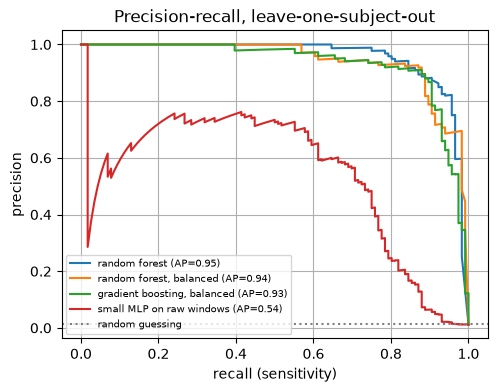

In [15]:
plt.figure(figsize=(5.5, 4))
for name, p in proba.items():
    prec, rec, _ = precision_recall_curve(yf, p)
    plt.plot(rec, prec, label=f"{name} (AP={average_precision_score(yf, p):.2f})")
plt.axhline(yf.mean(), color="gray", ls=":", label="random guessing")
plt.xlabel("recall (sensitivity)"); plt.ylabel("precision"); plt.legend(fontsize=7)
plt.title("Precision-recall, leave-one-subject-out"); plt.show()

In [16]:
# Sweep the alarm threshold of one model and watch the trade-off.
best = "random forest, balanced"
p = proba[best]
for th in [0.5, 0.3, 0.2, 0.1, 0.05]:
    evaluate(p >= th, f"{best} @{th}")

random forest, balanced @0.5       sens=0.84 spec=0.9992 prec=0.92 caught=52/58 FA/day*=  28.1
random forest, balanced @0.3       sens=0.89 spec=0.9976 prec=0.82 caught=54/58 FA/day*=  91.2
random forest, balanced @0.2       sens=0.91 spec=0.9959 prec=0.73 caught=56/58 FA/day*= 147.4
random forest, balanced @0.1       sens=0.98 spec=0.9938 prec=0.66 caught=58/58 FA/day*= 210.5
random forest, balanced @0.05      sens=0.98 spec=0.9903 prec=0.55 caught=58/58 FA/day*= 336.8


**What just happened?** Lowering the threshold raises sensitivity and the number of falls caught, at the price of more false alarms. A product team picks the operating point with clinicians and users: for example "catch at least 95% of falls in testing, with fewer than one false alarm per week in real-life trials".

**Careful:** choosing the threshold on the same out-of-fold predictions you report is slightly optimistic. In a real study, choose it on a **validation** set (or with nested cross-validation) and report on untouched test subjects. See [research methods: experiment design](../24_Research_Methods/02_experiment_design_for_ml.ipynb).

In [17]:
# Which features does the tree model rely on? (fit on all data just to inspect)
rf_all = RandomForestClassifier(n_estimators=40, min_samples_leaf=2, class_weight="balanced_subsample",
                                random_state=SEED, n_jobs=-1).fit(X, yf)
top = np.argsort(rf_all.feature_importances_)[::-1][:8]
print("top features:", [FEATURE_NAMES[i] for i in top])

top features: ['gm_max', 'am_max', 'am_range', 'am_kurt', 'max_jerk', 'gy_std', 'am_min', 'tilt_change']


The model leans on the same physics as the threshold rule (dip, spike, jerk, rotation) **plus** posture and stillness, combined in a way that is hard to hand-tune.

## 11. On-device (edge) constraints

Fall detection must run **on the device** (watch, pendant, phone): it must work without internet, react in seconds and last days on a small battery. **Edge AI** means running the model on the device itself instead of in the cloud.

| Constraint | Why it matters | Typical tricks |
|---|---|---|
| **Latency** | alarm within seconds | small windows, small models, early exit |
| **Battery** | users will not charge a pendant every night | low sampling rate, duty cycling, a cheap "wake-up" rule before the model, sensor-side motion interrupts |
| **Memory / model size** | microcontrollers may have only tens to hundreds of KB of RAM | few, shallow trees; small networks; **quantization** |
| **Compute** | no GPU, sometimes no floating-point unit | integer (int8) arithmetic, simple features |
| **Privacy** | raw motion can reveal health and habits | process on device, send only alerts |

Let us measure size and speed of some models, then try two classic tricks: **8-bit quantization** and a **cascade**.

In [18]:
def size_kb(model):
    return len(pickle.dumps(model)) / 1024

models = {
    "random forest 40 trees": rf_all,
    "random forest 15 trees, depth 6": RandomForestClassifier(n_estimators=15, max_depth=6,
        class_weight="balanced_subsample", random_state=SEED).fit(X, yf),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=100, class_weight="balanced",
                                                        random_state=SEED).fit(X, yf),
}
one = X[:1]
for name, mdl in models.items():
    t0 = time.perf_counter()
    for _ in range(50):
        mdl.predict_proba(one)
    ms = (time.perf_counter() - t0) / 50 * 1000
    print(f"{name:<34} size = {size_kb(mdl):8.1f} KB   latency per window (laptop, Python) = {ms:6.2f} ms")
t0 = time.perf_counter(); [window_features(A[i], Gy[i]) for i in range(200)]
print(f"feature extraction per window: {(time.perf_counter() - t0) / 200 * 1000:.2f} ms")

random forest 40 trees             size =    153.4 KB   latency per window (laptop, Python) =  12.44 ms
random forest 15 trees, depth 6    size =     35.0 KB   latency per window (laptop, Python) =   1.51 ms
gradient boosting                  size =    318.6 KB   latency per window (laptop, Python) =   1.10 ms


feature extraction per window: 0.79 ms


Python timings on a laptop are only a rough guide; on a microcontroller you would export the model to C (tools exist for both trees and small networks) and measure there. The **pickle** size also includes Python overhead; the real compiled model is usually much smaller. What matters here is the **relative** difference: a small, shallow forest is several times smaller and faster than a big one, usually for a small loss in accuracy.

### 8-bit quantization of the neural network

**What it is.** **Quantization** stores each weight as an 8-bit integer (-127..127) plus one scale factor per layer, instead of a 32-bit float. That is 4x smaller and runs fast on integer hardware. It is the same rounding idea as the ADC in notebook 01.

We train the MLP on subjects 0-7, test on 8-9, and compare float vs int8 weights using a hand-written forward pass (the kind of code that runs on a microcontroller).

In [19]:
train, test = gf < 8, gf >= 8
idx = np.concatenate([np.where(train)[0]] + [np.where(train & (yf == 1))[0]] * 9)
net = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-3, batch_size=256,
                                                    max_iter=25, random_state=SEED)).fit(R[idx], yf[idx])
scaler, mlp = net[0], net[1]

def forward(x, weights, biases):
    """Plain NumPy forward pass: ReLU hidden layers, sigmoid output (what MLPClassifier does)."""
    h = x
    for W, b in zip(weights[:-1], biases[:-1]):
        h = np.maximum(h @ W + b, 0)
    return 1 / (1 + np.exp(-(h @ weights[-1] + biases[-1]).ravel()))

def quantize_int8(W):
    scale = np.abs(W).max() / 127
    return np.round(W / scale).astype(np.int8), scale

q = [quantize_int8(W) for W in mlp.coefs_]
W_deq = [Wq.astype(np.float32) * s for Wq, s in q]             # what int8 weights represent
xs = scaler.transform(R[test])
p_float = forward(xs, mlp.coefs_, mlp.intercepts_)
p_int8 = forward(xs, W_deq, mlp.intercepts_)
n_float = sum(W.size for W in mlp.coefs_) * 4; n_int8 = sum(Wq.size for Wq, _ in q)
print(f"weights: float32 = {n_float / 1024:.1f} KB, int8 = {n_int8 / 1024:.1f} KB")
print("same as sklearn:", np.allclose(p_float, net.predict_proba(R[test])[:, 1]))
print(f"largest probability change from quantization: {np.abs(p_float - p_int8).max():.4f}")
print(f"alarms that flip at threshold 0.5: {((p_float >= 0.5) != (p_int8 >= 0.5)).sum()} of {test.sum()} windows")

weights: float32 = 56.1 KB, int8 = 14.0 KB
same as sklearn: True
largest probability change from quantization: 0.0120
alarms that flip at threshold 0.5: 0 of 1977 windows


### A cascade: a cheap rule first, the model only when needed

Most of the day nothing interesting happens. A tiny rule such as "|acc| peak above 1.5 g" can wake up the bigger model only for interesting windows. The model then runs on a small fraction of windows, which saves battery. The rule must be **loose** so it never blocks a real fall.

In [20]:
gate = X[:, FEATURE_NAMES.index("am_max")] > 1.5
p = proba["random forest, balanced"]
print(f"model needs to run on only {100 * gate.mean():.1f}% of windows")
print(f"falls that pass the gate: {gate[yf == 1].sum()} of {yf.sum()} fall windows")
evaluate(p >= 0.3, "random forest alone @0.3")
evaluate(gate & (p >= 0.3), "cascade: gate -> random forest @0.3");

model needs to run on only 9.7% of windows
falls that pass the gate: 116 of 116 fall windows
random forest alone @0.3           sens=0.89 spec=0.9976 prec=0.82 caught=54/58 FA/day*=  91.2
cascade: gate -> random forest @0.3 sens=0.89 spec=0.9976 prec=0.82 caught=54/58 FA/day*=  91.2


Same detection results, while the expensive model runs on only about a tenth of the windows. On a real device the gate can even run inside the IMU chip itself (many IMUs have built-in "motion detected" or "free-fall" interrupts), so the main processor can sleep most of the time.

## 12. Other ways to detect falls, and privacy

A wearable only works if it is **worn** (and charged). Other sensors avoid that, each with its own trade-offs:

| Sensor | How it sees a fall | Strengths | Weaknesses | Privacy |
|---|---|---|---|---|
| **Wearable IMU** (watch, pendant, phone) | dip + impact + posture, as in this notebook | cheap, works everywhere, also outdoors | must be worn and charged; wrist motion is noisy | good (only motion data) |
| **Camera** (RGB, depth) | pose estimation, person on the floor | rich information, can verify visually | lighting, occlusion; installation per room | **poor**: video of people at home, often in bathrooms and bedrooms |
| **mmWave radar** | **micro-Doppler** speed pattern of the body, height of the person | works in the dark, through light materials, no images | cost, multipath, needs ML on spectrograms | good: no recognisable image (see [notebook 03](03_radar_fmcw_range_doppler_and_micro_doppler.ipynb)) |
| **WiFi sensing (CSI)** | changes in the WiFi channel state information caused by body motion | uses existing routers | sensitive to furniture moves, still a research area for reliability | good-to-medium (no images, but can still reveal activity) |
| **Floor vibration / pressure mats** | impact vibration and position on the floor | invisible, nothing to wear | installation, floor type, pets | good |
| **Acoustic** (microphones) | impact sound, calls for help | cheap | noise, false triggers, speech privacy | medium-poor |

Many products combine sensors (for example, a watch plus a radar in the bathroom) and use **sensor fusion**, the topic of [notebook 05](05_sensor_fusion_kalman_filters_and_tracking.ipynb). There is also a quantum-ML experiment on the same kind of fall-detection features in [25_Quantum_AI/05](../25_Quantum_AI/05_quantum_ml_on_sensor_data_fall_detection.ipynb).

## 13. Deployment: from a model to a safe product

A fall detector is a **safety system**, not just a classifier. The surrounding process matters as much as the model.

```mermaid
flowchart LR
    D[Model detects<br/>possible fall] --> C[Device vibrates and asks:<br/>Are you OK? 30-60 s countdown]
    C -- user cancels --> L[Log the event<br/>no alert]
    C -- no answer --> E1[Call family / caregiver]
    E1 -- no answer --> E2[Call monitoring centre<br/>or emergency services<br/>with location]
    D --> M[Also: send a manual<br/>help button option]
```

- **Human confirmation.** A short "Are you OK?" countdown lets the user cancel false alarms, which reduces their cost a lot. But a person who is unconscious cannot answer, so silence must escalate.
- **Alert escalation.** Family first, then a monitoring centre, then emergency services, each with a time-out. Always keep a **manual help button**: no model catches every fall.
- **Monitoring after launch.** Track false-alarm and cancellation rates per user and device version. Falls in the real world look different from falls in a lab (see Bagalà et al., 2012), so expect lower real-life performance than lab numbers.
- **Fairness and coverage.** Test on the people who will use it: older adults, walking aids, wheelchairs, different body sizes. Young volunteers falling onto mats are not the target population.
- **Regulation (in general terms).** Software that claims to detect a medical event may count as a **medical device** in many countries (for example under the US FDA or the EU Medical Device Regulation), depending on the exact claims and the market. That brings requirements on clinical evidence, risk management, quality systems and post-market monitoring. Consumer "wellness" features usually make softer claims. Always check the current rules for your market with a regulatory expert.
- **Data protection.** Health-related sensor data is sensitive personal data under laws such as the GDPR. Keep processing on the device where possible, collect only what you need, and get clear consent. See [AI ethics and safety](../19_AI_Ethics_and_Safety/).

## 14. Recap

| Topic | Key point |
|---|---|
| Accelerometer | measures acceleration **including gravity**; at rest 1 g points "up" in the device frame |
| Gyroscope | rotation speed (deg/s); integrate it for angle, but it drifts (notebook 01) |
| Orientation | tilt from the gravity direction: `arccos(a_z / norm(a))` |
| Fall signature | free-fall dip -> impact spike -> stillness in a new posture |
| Look-alikes | jumps, chair plops, bed flops: always include them in training and test data |
| Windowing | e.g. 2.56 s windows, 50% overlap; longer = more context, slower reaction |
| Evaluation | **leave-one-subject-out**; random splits leak the person's identity |
| Rare events | accuracy is useless; report sensitivity, specificity, precision, PR curve, **false alarms per day** |
| Imbalance | class weights, oversampling, threshold moving, more hard negatives |
| Models | thresholds (cheap, explainable, brittle) -> trees on features (strong baseline) -> small neural nets on raw windows (need more data) |
| Edge | latency, battery, memory; int8 quantization; cheap gate + model cascade |
| Deployment | confirmation countdown, escalation, manual button, monitoring, medical-device rules, privacy |

## 15. Interview questions

1. **Why does an accelerometer read 1 g when lying still on a table?** It measures specific force: the table pushes it up against gravity. In free fall it reads about 0 g.
2. **Why is accuracy a bad metric for fall detection?** Falls are extremely rare, so a model that never alarms has about 99% accuracy and is useless. Use sensitivity, specificity, precision, PR-AUC and false alarms per day.
3. **What is leave-one-subject-out cross-validation and why use it?** Train on all people but one, test on the one left out, repeat. It measures performance on new people; random window splits leak personal style and mounting into the test set.
4. **How would you reduce false alarms without missing falls?** Add post-impact posture and stillness features, collect hard negatives (jumps, sitting down hard), tune the threshold on a validation set, use a confirmation countdown, and fuse other sensors.
5. **How do you handle class imbalance?** Class weights, oversampling the minority class (or SMOTE-style synthesis), undersampling, threshold moving, and above all more minority and hard-negative data. Evaluate with PR curves.
6. **What limits a model on a smartwatch?** Battery, RAM/flash, compute without a GPU, latency, and privacy. Use small models, int8 quantization, low sampling rates and cascades.
7. **Why might a lab-trained fall detector fail in real life?** Simulated falls by young volunteers onto mats differ from real falls by older people; device placement and daily activities differ too. Validate on real-world data and monitor after launch.
8. **Wearable vs radar for fall detection?** Wearables are cheap and work everywhere but must be worn; radar needs no wearable and preserves privacy better than cameras, but covers one room and needs careful ML on micro-Doppler signatures.

## 16. Further reading

- Davide Anguita, Alessandro Ghio, Luca Oneto, Xavier Parra and Jorge L. Reyes-Ortiz, "A Public Domain Dataset for Human Activity Recognition Using Smartphones", ESANN 2013 (the UCI HAR dataset).
- Andreas Bulling, Ulf Blanke and Bernt Schiele, "A tutorial on human activity recognition using body-worn inertial sensors", *ACM Computing Surveys*, 2014.
- Angela Sucerquia, José David López and Jesús Francisco Vargas-Bonilla, "SisFall: A Fall and Movement Dataset", *Sensors*, 2017.
- Fabio Bagalà et al., "Evaluation of Accelerometer-Based Fall Detection Algorithms on Real-World Falls", *PLoS ONE*, 2012.
- Raul Igual, Carlos Medrano and Inmaculada Plaza, "Challenges, issues and trends in fall detection systems", *BioMedical Engineering OnLine*, 2013.
- Nils Y. Hammerla, Shane Halloran and Thomas Plötz, "Deep, Convolutional, and Recurrent Models for Human Activity Recognition using Wearables", IJCAI 2016.
- World Health Organization, "Falls" fact sheet (who.int).

**Next:** [03 - Radar: FMCW, range-Doppler and micro-Doppler](03_radar_fmcw_range_doppler_and_micro_doppler.ipynb) detects the same falls with radio waves instead of a wearable.